# Recruiter Assistant — NLP system report
**Assignment 1 · Mariia Tsymbal**

A recruiter describes a vacancy in a chat; the system collects structured requirements,
searches 2 481 real (anonymised) CVs, ranks candidates with a transparent scorecard backed by
evidence from each CV, and writes a personalised LinkedIn message whose every claim is verified
against the CV.

| Section | Content |
|---|---|
| 1 | Task, scope and business logic |
| 2 | Data |
| 3 | System design — diagram, components, walk-through of one input |
| 4 | Evaluation of every component |
| 5 | CRISP-DM: how the process was applied, including every loop-back |
| 6 | How the AI coding agent was managed |
| 7 | Limitations and next steps · how to reproduce |

All numbers below are read from `eval/results/*.json`, produced by the scripts in `eval/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import SVG, Markdown, display

R = Path("eval/results")
load = lambda name: json.loads((R / f"{name}.json").read_text())
res = {n: load(n) for n in ["data_cleaning", "collector", "profiler", "retrieval", "ranker",
                            "reranker_llm", "outreach", "outreach_v1", "grounding_judge",
                            "benchmark_jobspecs_quality"]}
pd.set_option("display.precision", 3)

## 1. Task, scope and business logic

**Problem.** Screening CVs against a vacancy and writing first-contact messages are the two most
manual parts of a recruiter's day. Keyword filters miss candidates who describe the same skills
in other words; generic messages get ignored; LLM-written messages can invent facts about the
candidate, which is embarrassing and erodes trust.

**What the system does (in scope).**
1. **Collects requirements in a dialog** — title, must-have skills, minimum years, seniority
   (mandatory) and nice-to-have skills, domain, location (optional). It asks at most two
   follow-up questions per turn, never repeats a question, and starts searching once the
   mandatory slots are resolved or the recruiter says "search".
2. **Finds and ranks candidates** with a weighted scorecard (inspired by structured interview
   evaluation forms). Every criterion is shown with its score and the CV evidence.
3. **Explains** the top-10 with recruiter-style ratings (skills / experience / role fit, 1–5),
   a verified quote and the main concern.
4. **Writes a LinkedIn message** grounded only in CV facts; a checker verifies each claim.

**Scorecard (business rules, v2 — revised after evaluation, see §4.4).**

| Criterion | Weight | Measured as |
|---|---|---|
| Must-have skills | 0.25 | share found in the CV (skills dictionary with synonyms), with evidence snippets |
| Relevant experience | 0.25 | years from merged work date ranges vs required minimum (linear below) |
| Overall semantic match | 0.20 | embedding similarity of the CV to the vacancy |
| Role / title | 0.10 | similarity of the CV headline to the job title |
| Domain | 0.10 | similarity of CV passages to the domain |
| Nice-to-have skills | 0.05 | share found |
| Seniority | 0.05 | exact level 1, adjacent 0.5 |

A **hard knock-out** ("hide candidates with < 50 % of must-haves") was part of v1 but is now an
opt-in strict mode: on labelled data it rejected 87 % of good candidates (§4.4).

**Out of scope.** Sending messages, LinkedIn integration, scheduling, salary. Protected
attributes are never used: CVs are anonymised and the prompts forbid using them.

**Success criteria** were fixed before modelling (`docs/01_business_understanding.md`) and are
checked in §4.

## 2. Data

| | Candidate database | Ranking benchmark |
|---|---|---|
| Source | `opensporks/resumes` (Kaggle Resume Dataset, HF mirror) | `cnamuangtoun/resume-job-description-fit` (test split) |
| Size | 2 484 CVs, 24 job categories | 1 759 resume–JD pairs, 71 JDs, 476 unique resumes |
| Labels | category | **human fit labels**: No / Potential / Good Fit |
| Use | the searchable DB in the app | retrieval and ranking evaluation |

Open datasets were preferred to synthetic data: the benchmark gives independent human relevance
labels. Where no labels existed (CV profiles, vacancy requirements, message claims), small gold
sets were annotated by an **independent LLM annotator** (Claude, a different model family from
the Gemini model under test) following written guidelines, without access to the system's code
or prompts — documented in `eval/gold/README.md` and reported as *silver* labels.

**Data understanding → preparation rules (C0).** CVs are anonymised (employer = "Company Name",
no names) → messages must not use names or employers. Residual e-mails/phones → masked. Words
glued by PDF extraction → split at section headers and months. One empty CV and 2 duplicates →
dropped. Benchmark labels are *sparse* (each resume labelled for ~3.7 of 71 JDs), which matters
for interpreting recall (§4.3).

In [2]:
c = res["data_cleaning"]["candidate_db"]
pd.DataFrame({"before": c["before"], "after": c["after"]}).loc[
    ["emails", "phones", "glued_section_or_month", "exact_duplicates", "under_min_words"]]

,before,after
emails,19,0
phones,60,2
glued_section_or_month,27,0
exact_duplicates,2,0
under_min_words,1,0


## 3. System design

### 3.1 Data flow

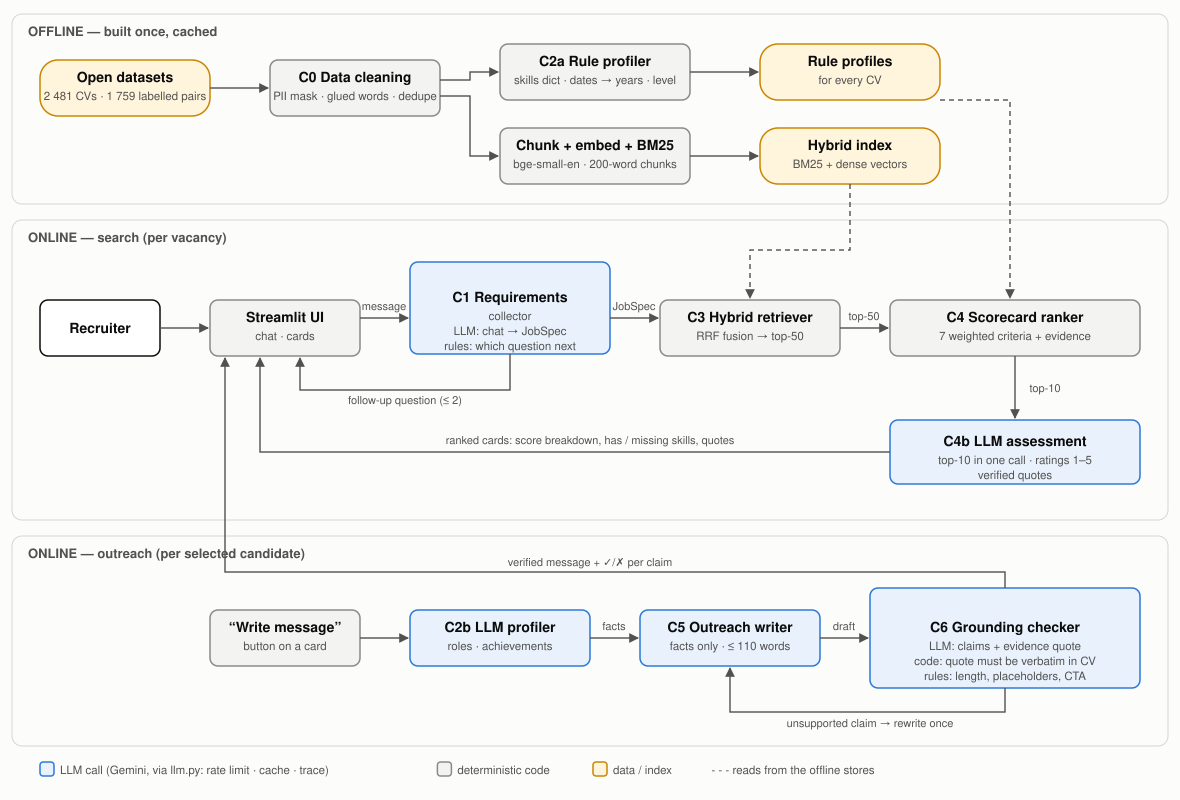

In [3]:
display(SVG(filename="docs/figures/architecture.svg"))

### 3.2 Components

| ID | Component | Purpose | Input → output | Model / tool calls |
|---|---|---|---|---|
| C0 | Data cleaning | usable, privacy-safe CV text | raw CSV → cleaned text | regex |
| C1 | Requirements collector | dialog → structured vacancy | chat → `JobSpec` + next question | **LLM** (1 call / message) + rule-based question policy |
| C2a | Rule profiler | cheap facts for *every* CV | CV → skills, years, seniority, headline | regex + skills dictionary |
| C2b | LLM profiler | rich facts for *shortlisted* CVs | CV → roles, achievements, education | **LLM**, cached |
| C3 | Hybrid retriever | high-recall search | `JobSpec` → top-50 | BM25 + bge-small-en embeddings, RRF fusion |
| C4 | Scorecard ranker | business-logic ranking + evidence | top-50 → ranked `CandidateScore` | deterministic + embeddings |
| C4b | LLM assessment | recruiter-style explanation | top-10 → ratings, quote, concern | **LLM**, 1 call for all 10 |
| C5 | Outreach writer | personalised message | `JobSpec` + C2b facts → message | **LLM** |
| C6 | Grounding checker | guardrail against invented facts | message + CV → claim verdicts | **LLM** judge + verbatim-quote check + rule checks |

Every LLM call goes through one module (`src/recruiter/llm.py`): Gemini via its OpenAI-compatible
API, structured JSON output validated by Pydantic, a client-side rate limiter (sliding 60 s window
and daily budget, persisted across runs — the free tier allows 15 RPM / 500 RPD), retries,
a disk cache (re-running evaluations is free) and a JSONL trace of every call.

**Why this design.** Rules where facts are countable (dates, skill names) — they proved more
accurate than the LLM (§4.2); embeddings where wording varies; the LLM where language must be
understood or produced (dialog, achievements, messages); and a second, partly deterministic
check wherever the LLM produces content shown to people.

### 3.3 Walk-through of one input

1. Recruiter: *"Need a senior accountant, must know accounting, Excel and QuickBooks."*
2. **C1** (1 LLM call) extracts `title=Accountant, seniority=senior, must=[accounting, excel,
   quickbooks]`; `min_years` is missing, so the rule policy asks *"How many years of relevant
   experience at minimum?"*. The recruiter answers "5+"; the JobSpec is re-extracted from the whole
   chat (corrections are handled naturally) and is complete.
3. **C3** builds a query from the JobSpec (must-haves boosted), ranks all 2 481 CVs with BM25 and
   with dense chunk embeddings, fuses both rankings with RRF → top-50.
4. **C4** computes the 7 criteria for each of the 50 from the C2a profiles and embeddings, attaches
   evidence (e.g. *"quickbooks: …Maintained general ledger in QuickBooks…"*) and sorts. The UI shows
   cards: score breakdown, "has / not found in CV", evidence, full CV.
5. Optional **C4b** (1 call): ratings 1–5, a quote (kept only if found verbatim in the CV), concern.
6. "Write LinkedIn message" on a card: **C2b** profiles the CV (1 call) → **C5** writes from facts
   only (1 call) → **C6** lists the claims with evidence quotes (1 call); a claim counts as
   supported only if its quote is verbatim in the CV; rule checks (≤ 120 words, no
   "Company Name"/[placeholders], a question). Any failure → one rewrite with the problems as
   feedback. The recruiter sees the message and ✓/✗ per claim.

## 4. Evaluation

Every component has its own script, metric choice, baseline or upper bound, and error analysis
(full write-up: `docs/05_evaluation.md`). Summary against the success criteria set in Phase 1:

In [4]:
col, pro, ret, ran = res["collector"], res["profiler"]["metrics"], res["retrieval"], res["ranker"]
rr, out, out1, judge = res["reranker_llm"], res["outreach"]["metrics"], res["outreach_v1"]["metrics"], res["grounding_judge"]
d = col["dialog"]
rows = [
    ("C0 cleaning", "docs with e-mail / phone after cleaning", f'{res["data_cleaning"]["candidate_db"]["after"]["emails"]} / {res["data_cleaning"]["candidate_db"]["after"]["phones"]}', "0 (2 phones = licence-number false positives)", "✓"),
    ("C1 collector", "title / seniority / years accuracy", f'{d["title_acc"]:.2f} / {d["seniority_acc"]:.2f} / {d["min_years_acc"]:.2f}', "slot F1 ≥ 0.80", "✓"),
    ("C1 collector", "must-have skills F1 (semantic)", f'{d["must_have_semantic"]["f1"]:.2f}', "≥ 0.80", "✗"),
    ("C1 collector", "mandatory slots resolved · mean turns", f'{d["mandatory_resolved_rate"]:.2f} · {d["mean_turns"]:.1f}', "≥ 80 % in ≤ 4 turns", "✓"),
    ("C2a rule profiler", "skills F1 / years MAE / seniority acc", f'{pro["C2a rules"]["skills"]["f1"]:.2f} / {pro["C2a rules"]["years_mae"]:.2f} y / {pro["C2a rules"]["seniority_accuracy"]:.2f}', "≥ 0.75 / ≤ 1.5 y / ≥ 0.70", "~ (skills F1 0.71)"),
    ("C2b LLM profiler", "achievements supported by CV", f'{pro["C2b LLM"]["achievements_supported"]:.2f}', "—", "✓"),
    ("C3 retriever", "Recall@50 (Good Fit) · MRR", f'{ret["metrics"]["hybrid/jobspec"]["recall@50"]:.3f} · {ret["metrics"]["hybrid/jobspec"]["mrr"]:.3f}', "≥ 0.80 (lower bound, sparse labels)", "✗"),
    ("C4 ranker", "NDCG@10 v2 · CV estimate", f'{ran["metrics"]["scorecard v2 (revised weights)"]["ndcg@10"]:.3f} · {ran["tuning_cv"]["all_criteria"]["mean_held_out_ndcg"]:.3f}', f'> C3 baseline {ran["metrics"]["retrieval: hybrid/jobspec (C3)"]["ndcg@10"]:.3f}', "✓"),
    ("C4b LLM assessment", "NDCG@10 if used for ordering", f'{rr["metrics"]["llm overall"]["ndcg@10"]:.3f}', "> scorecard", "✗ → explanations only"),
    ("C5 writer", "faithfulness (final) · personalised", f'{out["final"]["faithfulness_claim_level"]:.3f} · {out["final"]["personalised_>=2_supported_facts"]:.2f}', "≥ 0.95 · ≥ 90 %", "✓"),
    ("C6 checker (judge)", "Cohen's kappa vs independent labels", f'{judge["cohen_kappa"]:.2f}', "≥ 0.6", "✓"),
    ("C6 checker", "injected fabrications caught", f'{out["c6_fabrication_detection_rate"]:.2f}', "—", "✓"),
]
pd.DataFrame(rows, columns=["component", "metric", "value", "target", "met"])

,component,metric,value,target,met
0,C0 cleaning,docs with e-mail / phone after cleaning,0 / 2,0 (2 phones = licence-number false positives),✓
1,C1 collector,title / seniority / years accuracy,1.00 / 1.00 / 0.93,slot F1 ≥ 0.80,✓
2,C1 collector,must-have skills F1 (semantic),0.52,≥ 0.80,✗
3,C1 collector,mandatory slots resolved · mean turns,0.93 · 2.3,≥ 80 % in ≤ 4 turns,✓
4,C2a rule profiler,skills F1 / years MAE / seniority acc,0.71 / 0.39 y / 0.90,≥ 0.75 / ≤ 1.5 y / ≥ 0.70,~ (skills F1 0.71)
5,C2b LLM profiler,achievements supported by CV,1.00,—,✓
6,C3 retriever,Recall@50 (Good Fit) · MRR,0.455 · 0.322,"≥ 0.80 (lower bound, sparse labels)",✗
7,C4 ranker,NDCG@10 v2 · CV estimate,0.808 · 0.800,> C3 baseline 0.748,✓
8,C4b LLM assessment,NDCG@10 if used for ordering,0.801,> scorecard,✗ → explanations only
9,C5 writer,faithfulness (final) · personalised,1.000 · 0.95,≥ 0.95 · ≥ 90 %,✓


### 4.1 C1 Requirements collector
**Setup.** 15 benchmark JDs with gold requirements from the independent annotator. A simulator LLM
plays the recruiter who holds the JD: the first message gives only the role and 1–2 skills, later
messages answer only what is asked. Upper bound = the same extractor on the full JD text.
**Metrics:** per-slot accuracy, skill P/R/F1 (lexical and embedding-based matching — both reported
because the choice moves F1 by ~0.05), resolved mandatory slots, turns.

In [5]:
pd.DataFrame({"dialog (C1)": {k: (v["f1"] if isinstance(v, dict) else v) for k, v in d.items()},
              "full JD (upper bound)": {k: (v["f1"] if isinstance(v, dict) else v)
                                        for k, v in col["full_jd_extraction_upper_bound"].items()},
              "benchmark specs (v1, C3/C4 input)": {
                  k: (v["f1"] if isinstance(v, dict) else v)
                  for k, v in res["benchmark_jobspecs_quality"]["metrics"].items()}})

,dialog (C1),full JD (upper bound),"benchmark specs (v1, C3/C4 input)"
title_acc,1.000,1.000,0.933
seniority_acc,1.000,0.933,0.867
min_years_acc,0.933,1.000,0.933
must_have_lexical,0.477,0.641,0.650
nice_to_have_lexical,0.286,0.710,0.611
must_have_semantic,0.523,0.709,0.700
nice_to_have_semantic,0.286,0.710,0.611
completion_rate_mandatory,0.800,NaN,NaN
mandatory_resolved_rate,0.933,NaN,NaN
mean_turns,2.267,NaN,NaN


**Reading.** Scalar slots are essentially solved (title and level 100 %, years 93 %) in 2.3 turns.
The gap is **skill recall**: a recruiter in a chat names fewer requirements than the JD lists.
Evaluation found a real bug — the extractor *invented* "5 years" from the word "Senior", so the
question was never asked; prompt v2 forbids deriving years from the level. The collector now
also asks once for more skills when fewer than three are given. Next fix: propose typical skills
for the role for the recruiter to confirm.
**Input of the C3/C4 evals.** The benchmark JobSpecs were extracted with prompt v1 (last column):
must-haves on par with v2, but 1 JD of 15 worse on title, seniority and years and nice-to-have F1
0.10 lower — so C3/C4 are measured on slightly noisier input. Not re-extracted: ≈ 200 LLM calls.

### 4.2 C2a rule profiler vs C2b LLM profiler
30 CVs (15 categories × 2), silver labels with an auditable list of date ranges per CV.

In [6]:
keys = ["skills_f1", "years_mae", "years_within_1y", "seniority_accuracy", "headline_exact"]
tab = {}
for name in ["C2a rules", "C2b LLM"]:
    m = pro[name]
    tab[name] = {"skills_f1": m["skills"]["f1"], "skills_precision": m["skills"]["precision"],
                 "skills_recall": m["skills"]["recall"], "years_mae": m["years_mae"],
                 "years_within_1y": m["years_within_1y"], "seniority_accuracy": m["seniority_accuracy"],
                 "headline_exact": m["headline_exact"]}
pd.DataFrame(tab)

,C2a rules,C2b LLM
skills_f1,0.707,0.517
skills_precision,0.645,0.858
skills_recall,0.782,0.370
years_mae,0.387,1.323
years_within_1y,0.967,0.600
seniority_accuracy,0.900,0.700
headline_exact,0.867,0.967


**Reading.** The LLM is not better at everything: rules win on countable facts (years, level,
skill recall); the LLM wins on headlines and is the only source of grounded achievements
(100 % supported). Hence ranking uses C2a for all CVs and C2b only for the shortlist.
The first C2a run had years MAE 1.69; error analysis found date ranges written with a fullwidth
hyphen or soft hyphen (present in **1 205 of 2 481** DB CVs) and education periods counted as
work. After the fix MAE = 0.39 and CVs with "0 years" in the whole DB fell from 2.5 % to 1.3 % —
evidence that the fix generalises beyond the 30 CVs it was found on.

### 4.3 C3 Hybrid retriever
476 resumes, 28 JDs with ≥ 1 Good Fit (Recall, MRR), 61 JDs with ≥ 1 non-zero label (pool NDCG).

In [7]:
m = pd.DataFrame(ret["metrics"]).T[["recall@10", "recall@50", "mrr", "pool_ndcg@10"]]
display(m)
sig = ret["significance"]["recall@50: hybrid/jobspec vs hybrid/raw_jd"]
Markdown(f"JobSpec query vs raw JD text (hybrid): Recall@50 **{sig['mean_diff']:+.3f}**, "
         f"95 % CI [{sig['ci95'][0]:+.3f}, {sig['ci95'][1]:+.3f}] (paired bootstrap over JDs).")

,recall@10,recall@50,mrr,pool_ndcg@10
bm25/raw_jd,0.044,0.231,0.194,0.670
dense/raw_jd,0.052,0.361,0.198,0.709
hybrid/raw_jd,0.049,0.316,0.236,0.700
bm25/jobspec,0.098,0.397,0.268,0.728
dense/jobspec,0.145,0.445,0.283,0.757
hybrid/jobspec,0.116,0.455,0.322,0.748
random,0.021,0.105,NaN,0.574


JobSpec query vs raw JD text (hybrid): Recall@50 **+0.139**, 95 % CI [+0.052, +0.248] (paired bootstrap over JDs).

**Reading.** Dense beats BM25 (vocabulary mismatch in CVs); hybrid has the best Recall@50 and MRR.
Building the query from the extracted JobSpec instead of the raw JD (which is full of company
marketing and benefits) is the biggest single gain. Recall@50 = 0.46 is below the 0.80 target,
but it is a **lower bound**: 43 of the top-50 hits on average have *no label* for that JD and are
counted as misses (e.g. "Senior Tax Accountant": Recall@50 = 0 while pool NDCG@10 = 1.0 —
unlabelled accountants fill the top).

### 4.4 C4 Scorecard ranker and C4b LLM assessment
Labelled pools of 61 JDs (1 703 candidate–JD pairs), graded relevance 0/1/2.

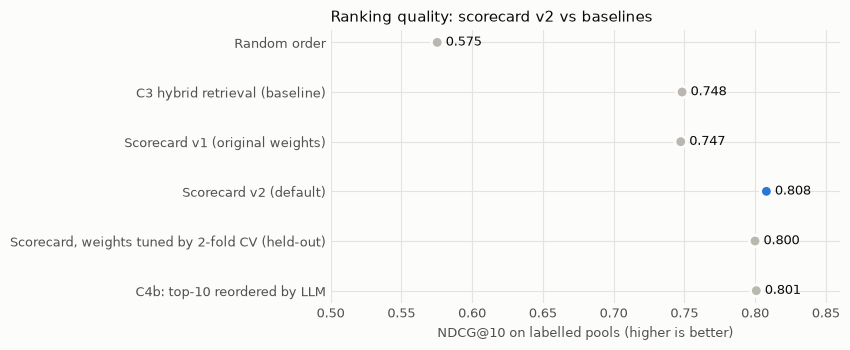

In [8]:
names = {"random": "Random order",
         "retrieval: hybrid/jobspec (C3)": "C3 hybrid retrieval (baseline)",
         "scorecard v1 (business weights)": "Scorecard v1 (original weights)",
         "scorecard v2 (revised weights)": "Scorecard v2 (default)"}
vals = {names[k]: ran["metrics"][k]["ndcg@10"] for k in names}
vals["Scorecard, weights tuned by 2-fold CV (held-out)"] = ran["tuning_cv"]["all_criteria"]["mean_held_out_ndcg"]
vals["C4b: top-10 reordered by LLM"] = rr["metrics"]["llm overall"]["ndcg@10"]
s = pd.Series(vals)

SURFACE, INK, INK2, GRID, ACCENT, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6", "#b9b7b0"
fig, ax = plt.subplots(figsize=(8.6, 3.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
# dot plot: position encodes the value, so a non-zero axis does not exaggerate differences
colors = [ACCENT if "default" in n else MUTED for n in s.index][::-1]
ax.scatter(s.values[::-1], s.index[::-1], s=70, color=colors, zorder=3,
           edgecolors=SURFACE, linewidths=2)
for y, v in enumerate(s.values[::-1]):
    ax.text(v + 0.006, y, f"{v:.3f}", va="center", fontsize=9, color=INK)
ax.set_xlim(0.5, 0.86)
ax.set_xlabel("NDCG@10 on labelled pools (higher is better)", color=INK2, fontsize=9)
ax.set_title("Ranking quality: scorecard v2 vs baselines", loc="left", color=INK, fontsize=11)
ax.tick_params(colors=INK2, labelsize=9, length=0)
ax.grid(axis="both", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for sp in ax.spines.values():
    sp.set_visible(False)
plt.tight_layout()
plt.show()

In [9]:
abl = {k.replace("ablation v2: without ", ""): v["ndcg@10"] for k, v in ran["metrics"].items() if k.startswith("ablation")}
base = ran["metrics"]["scorecard v2 (revised weights)"]["ndcg@10"]
display(pd.DataFrame({"NDCG@10 without it": abl, "delta": {k: v - base for k, v in abl.items()}}).sort_values("delta"))
ko = ran["knockout"]["knocked_out_share_by_label"]
Markdown(f"**Knock-out rule (< 50 % must-haves):** rejects {ko['2']:.0%} of Good Fit, {ko['1']:.0%} of "
         f"Potential and {ko['0']:.0%} of No Fit candidates — it does not discriminate.")

,NDCG@10 without it,delta
experience,0.752,-0.056
semantic,0.778,-0.030
domain,0.798,-0.010
title,0.800,-0.008
must_have,0.805,-0.003
seniority,0.806,-0.002
nice_to_have,0.814,0.006


**Knock-out rule (< 50 % must-haves):** rejects 87% of Good Fit, 90% of Potential and 90% of No Fit candidates — it does not discriminate.

**Reading.**
- Scorecard **v1** (original business weights) did not beat retrieval. Evaluation drove v2: the
  ablation shows **experience** and **semantic match** are the strongest signals; nice-to-have and
  seniority add little. v2 beats C3 by **+0.060 NDCG@10** (95 % CI [+0.012, +0.107]).
- v2 was chosen after seeing v1's results on the same JDs, so 0.808 is optimistic; the honest
  estimate is **2-fold cross-validation** (weights tuned on half of the JDs, tested on the other):
  **0.800**, still clearly above the baseline.
- The **knock-out** rule failed: in Good Fit CVs only 19 % of the JD's must-have skills are written
  literally (e.g. "kubernetes" in 4 of 66) — the labels reflect overall role fit, and real CVs omit
  listed tools. A filter that hides good people is bad business, so it became an opt-in mode and
  missing skills are shown as a warning.
- **C4b**: the LLM's ratings are sensible (mean 1.85 / 2.52 / 2.85 for No / Potential / Good,
  93 % of quotes verbatim) but reordering by them does not improve NDCG (−0.007, n.s.). Decision:
  the LLM explains, the scorecard orders; quotes not found in the CV are dropped.

### 4.5 C5 Outreach writer + C6 grounding checker
20 messages (10 benchmark JobSpecs × top-2 candidates from the DB).

In [10]:
t = pd.DataFrame({"v1 first draft": out1["first_draft"], "v1 final": out1["final"],
                  "v2 first draft": out["first_draft"], "v2 final": out["final"]})
t.loc[["faithfulness_claim_level", "messages_with_unsupported_claim", "constraint_compliance",
       "personalised_>=2_supported_facts", "mean_words"]]

,v1 first draft,v1 final,v2 first draft,v2 final
faithfulness_claim_level,0.926,0.965,0.959,1.00
messages_with_unsupported_claim,0.200,0.050,0.100,0.00
constraint_compliance,1.000,1.000,1.000,1.00
personalised_>=2_supported_facts,NaN,1.000,NaN,0.95
mean_words,NaN,68.450,NaN,64.85


**Reading.** In v1 the writer stated *computed* totals ("about 21.4 years") that no CV contains —
and C2b's years are off by 1.3 y on average. v2 does not pass computed years to the writer:
first-draft problems halved (20 % → 10 % of messages) and all final messages passed every check.

**Is the judge itself trustworthy?** C6 is an LLM judge, so it was validated twice: (1) against
independent claim labels (61 claims) and (2) by injecting a fabricated claim into every message.

In [11]:
pd.Series({k: judge[k] for k in ["n_claims", "gold_unsupported", "c6_flagged", "accuracy",
                                   "unsupported_precision", "unsupported_recall", "cohen_kappa"]}
          | {"injected fabrications caught": out["c6_fabrication_detection_rate"]})

n_claims                        61.000
gold_unsupported                 7.000
c6_flagged                       6.000
accuracy                         0.951
unsupported_precision            0.833
unsupported_recall               0.714
cohen_kappa                      0.742
injected fabrications caught     1.000
dtype: float64

C6 reliably catches invented facts and numbers (20/20 injected; kappa 0.74). Its errors are on
*overstatement* ("hands-on expertise with Java" when Java is only listed) — the hardest case for
both writer and judge — plus one false alarm on a combined claim.

## 5. CRISP-DM in this project

The full dated log with evidence for every decision is `docs/crisp_dm_log.md`; each phase has an
artefact (`docs/01_…`, `02_…`, `05_…`, code, `eval/`, `app.py`). Iteration was the norm —
every loop-back was triggered by a metric:

| # | Trigger (evaluation finding) | Went back to | Change |
|---|---|---|---|
| 1 | Data understanding: CVs anonymised, PII present | Business understanding | messages never use names/employers; PII masking |
| 2 | C3 Recall@50 0.32, query full of JD boilerplate | Modeling | query from LLM-extracted JobSpec (+0.14 Recall@50) |
| 3 | Success criterion assumed dense labels; labels sparse | Business understanding | recall reported as a lower bound; pool NDCG added |
| 4 | Knock-out rejects 87 % of Good Fit | Business understanding | knock-out opt-in; weights v2 with semantic criterion |
| 5 | C4b reordering does not beat scorecard | Modeling / deployment | LLM used for explanations only |
| 6 | C2a years MAE 1.69 (unicode dashes, education dates) | Data preparation / Modeling | parser fix → MAE 0.39; C4 re-evaluated |
| 7 | C1 dialogs ended after one turn (invented years) | Modeling | extractor prompt v2; ask for more skills |
| 8 | C5 claims with computed years unsupported | Modeling | writer no longer gets computed years |
| 9 | C1 "completion" counted correct empty slots as failures | Evaluation | metric redefined as "resolved" |

Deployment: Streamlit app (`app.py`) with the full pipeline and an LLM-budget counter;
README with setup and run instructions.

## 6. Managing the AI coding agent

The system was built with Claude Code. The agent was steered by files, not only by prompts:

- **`AGENTS.md`** (imported by `CLAUDE.md`) — the single source of truth for the agent: CRISP-DM
  phases with the artefact each must produce; hard rules (*no component without an evaluation*;
  never invent data silently; all LLM calls through `llm.py`; prompts versioned in `prompts/`;
  Pydantic contracts; grounding check for any generation; temperature 0 and caching for evals);
  code conventions; context management (never dump datasets into the conversation).
- **Rate-limit rule added after an incident.** An early ad-hoc script probed several models in a
  loop, bypassing the limiter. The rule now says: no bursts, estimate calls and ask before runs
  above 20 calls, test on 2–3 items first, stop on quota errors. Every later run followed it
  (smoke-test on 2–3 items, then the full run, with the call count reported).
- **Project skills** (`.claude/skills/`) encode repeatable workflows: `crisp-dm` (log template,
  loop-backs must cite a metric), `data-exploration`, `new-component` (contract → prompt → code →
  test → eval → wiring), `component-eval` (metric table by component type, gold set, baseline,
  error analysis of the 5 worst cases).
- **Independent sub-agents for gold labels.** Three annotation tasks (CV profiles, vacancy
  requirements, message claims) were delegated to separate agents with written guidelines and
  explicit instructions *not* to read the system's code, prompts or outputs — so labels are
  independent of the system they evaluate.
- **Human-in-the-loop decisions** stayed with the author: choice of task and LLM provider, the
  budget, approving runs, commits.

Reflection: written rules made the agent's behaviour predictable across sessions (the CRISP-DM
log and "eval for every component" were followed without reminders); the main failure mode was
the agent's tendency to start large or bursty runs, fixed by an explicit, testable rule.

## 7. Limitations and next steps

- **Silver labels.** CV profiles, vacancy requirements and claim labels come from an LLM annotator
  (different model family, guideline-driven, auditable), not humans; n = 15–61 per set.
- **Sparse benchmark labels** make corpus-level recall a lower bound; an LLM-judged sample of
  unlabelled hits would estimate true precision.
- **C1 skill recall** in dialog (F1 ≈ 0.5): suggest typical skills for confirmation.
- **Weights v2** were tuned on the same 61 JDs (the CV estimate is reported as the honest number).
- **Privacy:** e-mails/phones are masked, but one CV in the public dataset still contains a real
  name; name masking (NER) is not implemented. Gold files store CV ids, not such texts.
- **LLM-only explanations** use a 450-word CV excerpt; giving the full CV may improve C4b.

### How to reproduce
```bash
uv sync && cp .env.example .env            # add GEMINI_API_KEY
uv run python scripts/download_data.py && uv run python scripts/prepare_data.py
uv run pytest -q                           # 39 tests, no network
uv run python eval/eval_retrieval.py       # and the other eval/*.py scripts (LLM calls are cached)
uv run streamlit run app.py
```